In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
# ============================================================
# STEP 1 : Clone TinyLLM Repository
# ============================================================

!git clone https://github.com/shaikkoduruasif114/TinyLLM.git

%cd TinyLLM

print("Current Directory:")
!pwd

print("\nProject Structure:")
!find . -maxdepth 2 -type f | sort

Cloning into 'TinyLLM'...
remote: Enumerating objects: 38, done.
remote: Counting objects: 100% (38/38), done.
remote: Compressing objects: 100% (31/31), done.
remote: Total 38 (delta 7), reused 36 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (38/38), 63.90 KiB | 3.04 MiB/s, done.
Resolving deltas: 100% (7/7), done.
/kaggle/working/TinyLLM
Current Directory:
/kaggle/working/TinyLLM

Project Structure:
./01_forward_pass.ipynb
./analysis/attention_viz.py
./analysis/embedding_similarity.py
./analysis/perplexity_vs_length.py
./dataloader.py
./dataset.py
./data/train.py
./data/val.py
./.git/config
./.git/description
./.git/HEAD
./.gitignore
./.git/index
./.git/packed-refs
./merges.json
./model/attention.py
./model/block.py
./model/feedforward.py
./model/gpt.py
./model/positional_encoding.py
./prepare_data.py
./scripts/test_attention_compare.py
./tokeniser/bpe_tokeniser.py
./tokeniser/test_tokeniser.py
./tokeniser/train_tokeniser.py
./train.py
./vocab.json


In [2]:
# ============================================================
# STEP 2 : Restore Checkpoints + Encoded Dataset
# ============================================================

import shutil
import os

BACKUP = "/kaggle/input/datasets/shaikkoduruasif114/tiny-backup"

os.makedirs("checkpoints", exist_ok=True)
os.makedirs("data", exist_ok=True)

# Copy checkpoints
for f in os.listdir(f"{BACKUP}/checkpoints"):
    shutil.copy(
        f"{BACKUP}/checkpoints/{f}",
        f"checkpoints/{f}"
    )

# Copy encoded dataset
shutil.copy(f"{BACKUP}/encoded_data/train.npy", "data/train.npy")
shutil.copy(f"{BACKUP}/encoded_data/val.npy", "data/val.npy")

# Copy tokenizer
shutil.copy(f"{BACKUP}/encoded_data/vocab.json", "vocab.json")
shutil.copy(f"{BACKUP}/encoded_data/merges.json", "merges.json")

print("="*60)
print("Project Restored Successfully")
print("="*60)

!ls -lh checkpoints
print()
!ls -lh data

Project Restored Successfully
total 843M
-rw-r--r-- 1 root root 141M Aug  7 20:27 learned_best.pt
-rw-r--r-- 1 root root 141M Aug  7 20:27 learned_latest.pt
-rw-r--r-- 1 root root 141M Aug  7 20:27 rope_best.pt
-rw-r--r-- 1 root root 141M Aug  7 20:27 rope_latest.pt
-rw-r--r-- 1 root root 141M Aug  7 20:27 sinusoidal_best.pt
-rw-r--r-- 1 root root 141M Aug  7 20:27 sinusoidal_latest.pt

total 39M
-rw-r--r-- 1 root root  38M Aug  7 20:27 train.npy
-rw-r--r-- 1 root root    0 Aug  7 20:26 train.py
-rw-r--r-- 1 root root 393K Aug  7 20:27 val.npy
-rw-r--r-- 1 root root    0 Aug  7 20:26 val.py


In [3]:
# ============================================================
# STEP 3 : Verify Checkpoint Loading (CPU First)
# ============================================================

import torch
import sys

sys.path.append(".")

from model.gpt import GPT

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

ckpt = torch.load(
    "checkpoints/rope_best.pt",
    map_location="cpu"      # <-- IMPORTANT
)

print("\nCheckpoint loaded successfully.")

print("\nStored configuration:")

for k, v in ckpt["config"].items():
    print(f"{k:20}: {v}")

print("\nBest Validation Loss:",
      ckpt["best_val_loss"])

model = GPT(ckpt["config"])

model.load_state_dict(
    ckpt["model_state_dict"],
    strict=True
)

print("\nWeights loaded successfully.")

model = model.to(DEVICE)

print("Model moved to", DEVICE)

model.eval()

print("\nEverything works!")

Device: cuda

Checkpoint loaded successfully.

Stored configuration:
vocab_size          : 4096
block_size          : 128
n_embd              : 384
n_head              : 6
n_layer             : 6
dropout             : 0.1
pos_encoding        : rope

Best Validation Loss: 2.0371786064031174
Model parameters: 12,220,416

Weights loaded successfully.
Model moved to cuda

Everything works!


In [4]:
# ============================================================
# STEP 4 : Deterministic Validation Dataset
# ============================================================

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

class DeterministicValDataset(Dataset):

    def __init__(self, data_path, block_size, max_samples=784):

        self.data = np.load(data_path)

        self.block_size = block_size

        self.starts = list(
            range(
                0,
                len(self.data) - block_size - 1,
                block_size
            )
        )

        # Keep same number of windows for every experiment
        self.starts = self.starts[:max_samples]

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, idx):

        s = self.starts[idx]

        x = self.data[s:s+self.block_size]
        y = self.data[s+1:s+self.block_size+1]

        return (
            torch.tensor(x, dtype=torch.long),
            torch.tensor(y, dtype=torch.long)
        )


def create_loader(block_size):

    return DataLoader(
        DeterministicValDataset(
            "data/val.npy",
            block_size
        ),
        batch_size=32,
        shuffle=False,
        pin_memory=True
    )

print("✓ Validation loader ready.")

✓ Validation loader ready.


In [5]:
for L in [64,128,192,256]:

    loader = create_loader(L)

    x,y = next(iter(loader))

    print("="*50)
    print("Context:",L)
    print("Batch:",x.shape)
    print("Samples:",len(loader.dataset))

Context: 64
Batch: torch.Size([32, 64])
Samples: 784
Context: 128
Batch: torch.Size([32, 128])
Samples: 784
Context: 192
Batch: torch.Size([32, 192])
Samples: 784
Context: 256
Batch: torch.Size([32, 256])
Samples: 784


In [6]:
# ============================================================
# STEP 6 : Evaluate RoPE @ 128
# ============================================================

import math

@torch.no_grad()
def evaluate(model, loader):

    model.eval()

    total_loss = 0
    total_tokens = 0

    for x, y in loader:

        x = x.to(DEVICE)
        y = y.to(DEVICE)

        _, loss, _ = model(x, y)

        total_loss += loss.item() * y.numel()
        total_tokens += y.numel()

    avg_loss = total_loss / total_tokens

    return avg_loss, math.exp(avg_loss)


loader = create_loader(128)

loss, ppl = evaluate(model, loader)

print("="*60)
print("RoPE @ 128")
print("="*60)

print("Validation Loss :", loss)
print("Perplexity      :", ppl)

RoPE @ 128
Validation Loss : 1.9462596688951765
Perplexity      : 7.002447066503277


In [7]:
# ============================================================
# STEP 6 : Runtime Evaluation Patch (No File Modification)
# ============================================================

import math
import torch
import torch.nn.functional as F

from model.attention import MultiHeadAttention
from model.positional_encoding import LearnedPositionalEncoding

# ------------------------------------------------------------
# Save original methods
# ------------------------------------------------------------

_original_attention_forward = MultiHeadAttention.forward
_original_learned_forward = LearnedPositionalEncoding.forward

# ------------------------------------------------------------
# Dynamic Attention Mask
# ------------------------------------------------------------

def attention_forward_eval(self, x):

    B, T, C = x.size()

    q, k, v = self.c_attn(x).split(self.n_embd, dim=2)

    q = q.view(B, T, self.n_head, self.head_dim).transpose(1,2)
    k = k.view(B, T, self.n_head, self.head_dim).transpose(1,2)
    v = v.view(B, T, self.n_head, self.head_dim).transpose(1,2)

    if self.rotary_emb is not None:
        q, k = self.rotary_emb(q, k)

    att = (q @ k.transpose(-2,-1)) / math.sqrt(self.head_dim)

    # -------- Dynamic causal mask --------
    mask = torch.tril(
        torch.ones(T, T, device=x.device, dtype=torch.bool)
    ).view(1,1,T,T)

    att = att.masked_fill(~mask, float("-inf"))

    att = F.softmax(att, dim=-1)

    att = self.attn_dropout(att)

    y = att @ v

    y = (
        y.transpose(1,2)
         .contiguous()
         .view(B,T,C)
    )

    y = self.resid_dropout(self.c_proj(y))

    return y, att


# ------------------------------------------------------------
# Learned Position Clamp
# ------------------------------------------------------------

def learned_forward_eval(self, x):

    seq_len = x.size(1)

    positions = torch.arange(
        seq_len,
        device=x.device,
        dtype=torch.long
    )

    positions = positions.clamp(
        max=self.pos_embed.num_embeddings - 1
    )

    positions = positions.unsqueeze(0)

    return x + self.pos_embed(positions)


# ------------------------------------------------------------
# Activate evaluation patch
# ------------------------------------------------------------

MultiHeadAttention.forward = attention_forward_eval
LearnedPositionalEncoding.forward = learned_forward_eval

print("="*60)
print("Evaluation patch activated.")
print("✓ Dynamic Attention Mask")
print("✓ Learned Position Clamp")
print("="*60)

Evaluation patch activated.
✓ Dynamic Attention Mask
✓ Learned Position Clamp


In [8]:
# ============================================================
# STEP 7 : Universal Model Loader
# ============================================================

import gc
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def load_model(name):

    checkpoint = torch.load(
        f"checkpoints/{name}_best.pt",
        map_location="cpu"          # Always load on CPU first
    )

    config = checkpoint["config"]

    model = GPT(config)

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model = model.to(DEVICE)
    model.eval()

    return model


def unload_model(model):

    del model

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("✓ Universal loader ready.")

✓ Universal loader ready.


In [9]:
# ============================================================
# STEP 8 : Universal Evaluation
# ============================================================

import math

@torch.no_grad()
def evaluate(model, loader):

    model.eval()

    total_loss = 0.0
    total_tokens = 0

    for x, y in loader:

        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        _, loss, _ = model(x, y)

        tokens = y.numel()

        total_loss += loss.item() * tokens
        total_tokens += tokens

    avg_loss = total_loss / total_tokens
    perplexity = math.exp(avg_loss)

    return avg_loss, perplexity

print("✓ Evaluation function ready.")

✓ Evaluation function ready.


In [10]:
print("Attention Forward :", MultiHeadAttention.forward.__name__)
print("Learned Forward  :", LearnedPositionalEncoding.forward.__name__)

Attention Forward : attention_forward_eval
Learned Forward  : learned_forward_eval


In [12]:
# ============================================================
# PATCH 1 : Dynamic Causal Mask
# ============================================================

from pathlib import Path

path = Path("model/attention.py")

text = path.read_text()

old = """        # Causal mask (upper triangle set to -inf)
        # self.bias is (1, 1, block_size, block_size), we slice to T
        att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float('-inf'))"""

new = """        # Dynamic causal mask
        mask = torch.tril(
            torch.ones(T, T, device=x.device, dtype=torch.bool)
        ).view(1, 1, T, T)

        att = att.masked_fill(~mask, float("-inf"))"""

if old in text:
    text = text.replace(old, new)
    path.write_text(text)
    print("✅ attention.py patched successfully.")
else:
    print("⚠️ Pattern not found. File may already be patched.")

✅ attention.py patched successfully.


In [13]:
with open("model/attention.py") as f:
    code = f.read()

print("Dynamic mask present:", "mask = torch.tril" in code)

Dynamic mask present: True


In [14]:
# ============================================================
# PATCH 2 : Learned PE Clamp
# ============================================================

from pathlib import Path

path = Path("model/positional_encoding.py")

text = path.read_text()

old = """        positions = torch.arange(seq_len, device=x.device, dtype=torch.long).unsqueeze(0)
        return x + self.pos_embed(positions)"""

new = """        positions = torch.arange(
            seq_len,
            device=x.device,
            dtype=torch.long
        )

        positions = positions.clamp(
            max=self.pos_embed.num_embeddings - 1
        )

        positions = positions.unsqueeze(0)

        return x + self.pos_embed(positions)"""

if old in text:
    text = text.replace(old, new)
    path.write_text(text)
    print("✅ positional_encoding.py patched successfully.")
else:
    print("⚠️ Pattern not found. File may already be patched.")

✅ positional_encoding.py patched successfully.


In [15]:
with open("model/positional_encoding.py") as f:
    code = f.read()

print("Clamp present:", "clamp(" in code)

Clamp present: True


In [16]:
import importlib

import model.attention
import model.positional_encoding
import model.block
import model.gpt

importlib.reload(model.attention)
importlib.reload(model.positional_encoding)
importlib.reload(model.block)
importlib.reload(model.gpt)

from model.gpt import GPT

print("✅ Modules reloaded.")

✅ Modules reloaded.


In [17]:
# ============================================================
# Reload Model After Patching
# ============================================================

import gc
import torch

# Clear old model if it exists
try:
    del rope_model
except:
    pass

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("GPU cache cleared.")

# Reload fresh model
rope_model = load_model("rope")

print("Fresh RoPE model loaded.")

GPU cache cleared.
Model parameters: 12,220,416
Fresh RoPE model loaded.


In [20]:
# ============================================================
# Inspect checkpoint state_dict shapes
# ============================================================

ckpt = torch.load("checkpoints/rope_best.pt", map_location="cpu")

for k, v in ckpt["model_state_dict"].items():
    if "bias" in k or "pos_embed" in k:
        print(k, tuple(v.shape))

blocks.0.ln1.bias (384,)
blocks.0.ln2.bias (384,)
blocks.0.attn.bias (1, 1, 128, 128)
blocks.0.attn.c_attn.bias (1152,)
blocks.0.attn.c_proj.bias (384,)
blocks.0.ffn.net.0.bias (1536,)
blocks.0.ffn.net.2.bias (384,)
blocks.1.ln1.bias (384,)
blocks.1.ln2.bias (384,)
blocks.1.attn.bias (1, 1, 128, 128)
blocks.1.attn.c_attn.bias (1152,)
blocks.1.attn.c_proj.bias (384,)
blocks.1.ffn.net.0.bias (1536,)
blocks.1.ffn.net.2.bias (384,)
blocks.2.ln1.bias (384,)
blocks.2.ln2.bias (384,)
blocks.2.attn.bias (1, 1, 128, 128)
blocks.2.attn.c_attn.bias (1152,)
blocks.2.attn.c_proj.bias (384,)
blocks.2.ffn.net.0.bias (1536,)
blocks.2.ffn.net.2.bias (384,)
blocks.3.ln1.bias (384,)
blocks.3.ln2.bias (384,)
blocks.3.attn.bias (1, 1, 128, 128)
blocks.3.attn.c_attn.bias (1152,)
blocks.3.attn.c_proj.bias (384,)
blocks.3.ffn.net.0.bias (1536,)
blocks.3.ffn.net.2.bias (384,)
blocks.4.ln1.bias (384,)
blocks.4.ln2.bias (384,)
blocks.4.attn.bias (1, 1, 128, 128)
blocks.4.attn.c_attn.bias (1152,)
blocks.4.attn.c_

In [21]:
# ============================================================
# Build 256-context Evaluation Model
# ============================================================

import copy
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def load_eval_model(model_name, context_length):

    ckpt = torch.load(
        f"checkpoints/{model_name}_best.pt",
        map_location="cpu"
    )

    config = copy.deepcopy(ckpt["config"])
    config["block_size"] = context_length

    model = GPT(config)

    state = ckpt["model_state_dict"]

    # ---------------------------------------------------------
    # Remove attention bias buffers (fixed causal masks)
    # ---------------------------------------------------------
    keys_to_remove = []

    for k in state.keys():
        if k.endswith("attn.bias"):
            keys_to_remove.append(k)

    for k in keys_to_remove:
        del state[k]

    missing, unexpected = model.load_state_dict(
        state,
        strict=False
    )

    print("="*60)
    print(model_name.upper())
    print("="*60)
    print("Missing keys:")
    print(missing)
    print("\nUnexpected keys:")
    print(unexpected)

    model = model.to(DEVICE)
    model.eval()

    return model

print("Ready.")

Ready.


In [22]:
rope256 = load_eval_model("rope",256)

Model parameters: 12,220,416
ROPE
Missing keys:
['blocks.0.attn.bias', 'blocks.0.attn.c_attn.bias', 'blocks.1.attn.bias', 'blocks.1.attn.c_attn.bias', 'blocks.2.attn.bias', 'blocks.2.attn.c_attn.bias', 'blocks.3.attn.bias', 'blocks.3.attn.c_attn.bias', 'blocks.4.attn.bias', 'blocks.4.attn.c_attn.bias', 'blocks.5.attn.bias', 'blocks.5.attn.c_attn.bias']

Unexpected keys:
[]


In [36]:
# ============================================================
# Evaluate ONE loaded model on all context lengths
# ============================================================

import pandas as pd

lengths = [64, 128, 192, 256]

results = []

for L in lengths:

    print(f"Evaluating @ {L}")

    loader = create_loader(L)

    loss, ppl = evaluate(rope256, loader)

    results.append({
        "Context Length": L,
        "Validation Loss": loss,
        "Perplexity": ppl
    })

rope_df = pd.DataFrame(results)

display(rope_df)

Evaluating @ 64
Evaluating @ 128
Evaluating @ 192
Evaluating @ 256


,Context Length,Validation Loss,Perplexity
0,64,1.933844,6.916048
1,128,1.946260,7.002447
2,192,2.018104,7.524043
3,256,2.245156,9.441891


In [37]:
# ============================================================
# Remove RoPE model
# ============================================================

del rope256

import gc
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("RoPE model removed.")

RoPE model removed.


In [38]:
learned256 = load_eval_model("learned", 256)

Model parameters: 12,318,720


In [39]:
# ============================================================
# Evaluate Learned at all context lengths
# ============================================================

import pandas as pd

lengths = [64, 128, 192, 256]

results = []

for L in lengths:

    print(f"Evaluating @ {L}")

    loader = create_loader(L)

    loss, ppl = evaluate(learned256, loader)

    results.append({
        "Context Length": L,
        "Validation Loss": loss,
        "Perplexity": ppl
    })

learned_df = pd.DataFrame(results)

display(learned_df)

Evaluating @ 64
Evaluating @ 128
Evaluating @ 192
Evaluating @ 256


,Context Length,Validation Loss,Perplexity
0,64,1.948525,7.018327
1,128,1.954924,7.063384
2,192,2.303715,10.011307
3,256,2.674893,14.510801


In [40]:
# ============================================================
# Remove Learned Model
# ============================================================

del learned256

import gc
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Learned model removed.")

Learned model removed.


In [41]:
sin256 = load_eval_model("sinusoidal", 256)

Model parameters: 12,220,416


In [42]:
# ============================================================
# Evaluate Sinusoidal
# ============================================================

import pandas as pd

lengths = [64, 128, 192, 256]

results = []

for L in lengths:

    print(f"Evaluating @ {L}")

    loader = create_loader(L)

    loss, ppl = evaluate(sin256, loader)

    results.append({
        "Context Length": L,
        "Validation Loss": loss,
        "Perplexity": ppl
    })

sin_df = pd.DataFrame(results)

display(sin_df)

Evaluating @ 64
Evaluating @ 128
Evaluating @ 192
Evaluating @ 256


,Context Length,Validation Loss,Perplexity
0,64,2.188436,8.921249
1,128,2.212703,9.140389
2,192,4.210120,67.364614
3,256,5.319947,204.373088


In [43]:
# ============================================================
# Combine All Results
# ============================================================

rope_df["Model"] = "RoPE"
learned_df["Model"] = "Learned"
sin_df["Model"] = "Sinusoidal"

results_df = pd.concat(
    [rope_df, learned_df, sin_df],
    ignore_index=True
)

display(results_df)

,Context Length,Validation Loss,Perplexity,Model
0,64,1.933844,6.916048,RoPE
1,128,1.946260,7.002447,RoPE
2,192,2.018104,7.524043,RoPE
3,256,2.245156,9.441891,RoPE
4,64,1.948525,7.018327,Learned
5,128,1.954924,7.063384,Learned
6,192,2.303715,10.011307,Learned
7,256,2.674893,14.510801,Learned
8,64,2.188436,8.921249,Sinusoidal
9,128,2.212703,9.140389,Sinusoidal


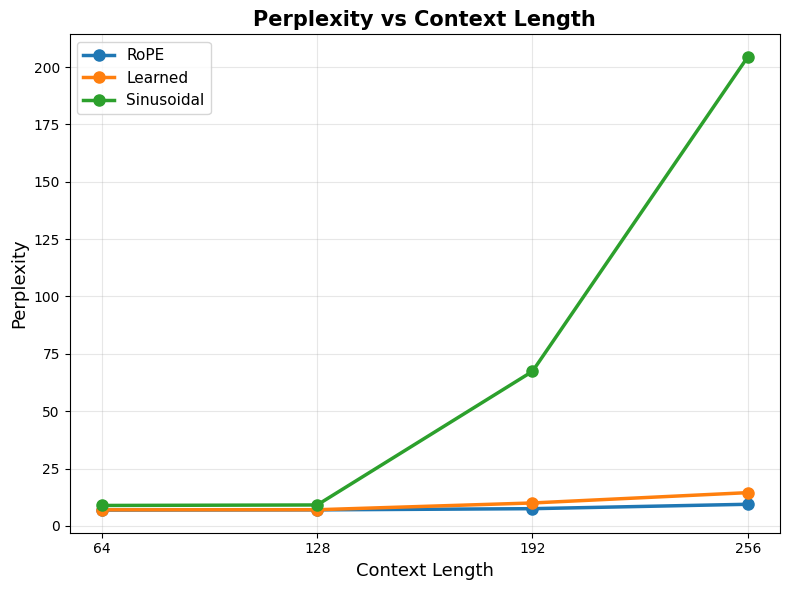

In [44]:
# ============================================================
# Perplexity vs Context Length
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

for model in ["RoPE", "Learned", "Sinusoidal"]:

    data = results_df[results_df["Model"] == model]

    plt.plot(
        data["Context Length"],
        data["Perplexity"],
        marker="o",
        linewidth=2.5,
        markersize=8,
        label=model
    )

plt.xlabel("Context Length", fontsize=13)
plt.ylabel("Perplexity", fontsize=13)

plt.title(
    "Perplexity vs Context Length",
    fontsize=15,
    weight="bold"
)

plt.xticks([64,128,192,256])

plt.grid(True, alpha=0.3)

plt.legend(fontsize=11)

plt.tight_layout()

plt.savefig(
    "perplexity_vs_context_length.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [45]:
results_df.to_csv(
    "perplexity_vs_context_length.csv",
    index=False
)

print("Saved:")
print("  perplexity_vs_context_length.csv")
print("  perplexity_vs_context_length.png")

Saved:
  perplexity_vs_context_length.csv
  perplexity_vs_context_length.png


In [46]:
# ============================================================
# Find tokenizer implementation
# ============================================================

from pathlib import Path

print(Path("tokeniser/bpe_tokeniser.py").read_text())

from collections import Counter
import json


class BPETokenizer:

    ############################################################
    # Constructor
    ############################################################
    def __init__(self):

        self.special_tokens = [
            "<PAD>",
            "<BOS>",
            "<EOS>",
            "<UNK>"
        ]

        self.vocab = set()
        self.merges = []
        self.merge_ranks = {}
        self.cache = {}

        self.token_to_id = {}
        self.id_to_token = {}

    ############################################################
    # Count adjacent pairs
    ############################################################
    def count_pairs(self, corpus):

        pair_counts = Counter()

        for word, freq in corpus.items():

            for i in range(len(word) - 1):

                pair = (word[i], word[i + 1])

                pair_counts[pair] += freq

        return pair_counts

    ###############################

In [47]:
# ============================================================
# Load Tokenizer
# ============================================================

from tokeniser.bpe_tokeniser import BPETokenizer

tokenizer = BPETokenizer()

tokenizer.load(
    "vocab.json",
    "merges.json"
)

print("Vocabulary Size:", len(tokenizer.token_to_id))

Vocabulary Size: 4096


In [48]:
import inspect
from model.gpt import GPT

print(inspect.getsource(GPT.forward))

    def forward(self, idx, targets=None):
        """
        Forward pass.

        Args:
            idx: (B, T) integer token ids
            targets: (B, T) integer token ids shifted by 1
                     If provided, compute and return loss

        Returns:
            logits: (B, T, vocab_size)
            loss: scalar cross entropy loss (or None if targets not provided)
        """
        B, T = idx.size()

        # ── Token Embeddings ──────────────────────
        # (B, T) -> (B, T, n_embd)
        x = self.token_embedding(idx)

        # ── Positional Encoding ───────────────────
        # Add positional info (not for RoPE — handled inside attention)
        if self.pos_encoding is not None:
            x = self.pos_encoding(x)

        # ── Transformer Blocks ────────────────────
        # Collect attention weights from all layers
        # for visualization later
        all_attention_weights = []

        for block in self.blocks:
            x, att = block(x)
     

In [49]:
# ============================================================
# Encode a Sample Sentence
# ============================================================

sentence = "Once upon a time there was a"

tokens = tokenizer.encode(sentence)

print("Tokens:")
print(tokens)

import torch

x = torch.tensor(tokens, dtype=torch.long).unsqueeze(0).to(DEVICE)

print("Input Shape:", x.shape)

Tokens:
[338, 3783, 457, 3619, 3574, 3876, 457]
Input Shape: torch.Size([1, 7])


In [51]:
# ============================================================
# Reload RoPE Evaluation Model
# ============================================================

import gc

try:
    del learned256
except:
    pass

try:
    del sin256
except:
    pass

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

rope256 = load_eval_model("rope", 256)

print("RoPE model loaded successfully.")

Model parameters: 12,220,416
RoPE model loaded successfully.


In [52]:
with torch.no_grad():

    logits, loss, attention = rope256(x)

print("Number of Layers :", len(attention))

print("Layer 1 Shape :", attention[0].shape)

Number of Layers : 6
Layer 1 Shape : torch.Size([1, 6, 7, 7])


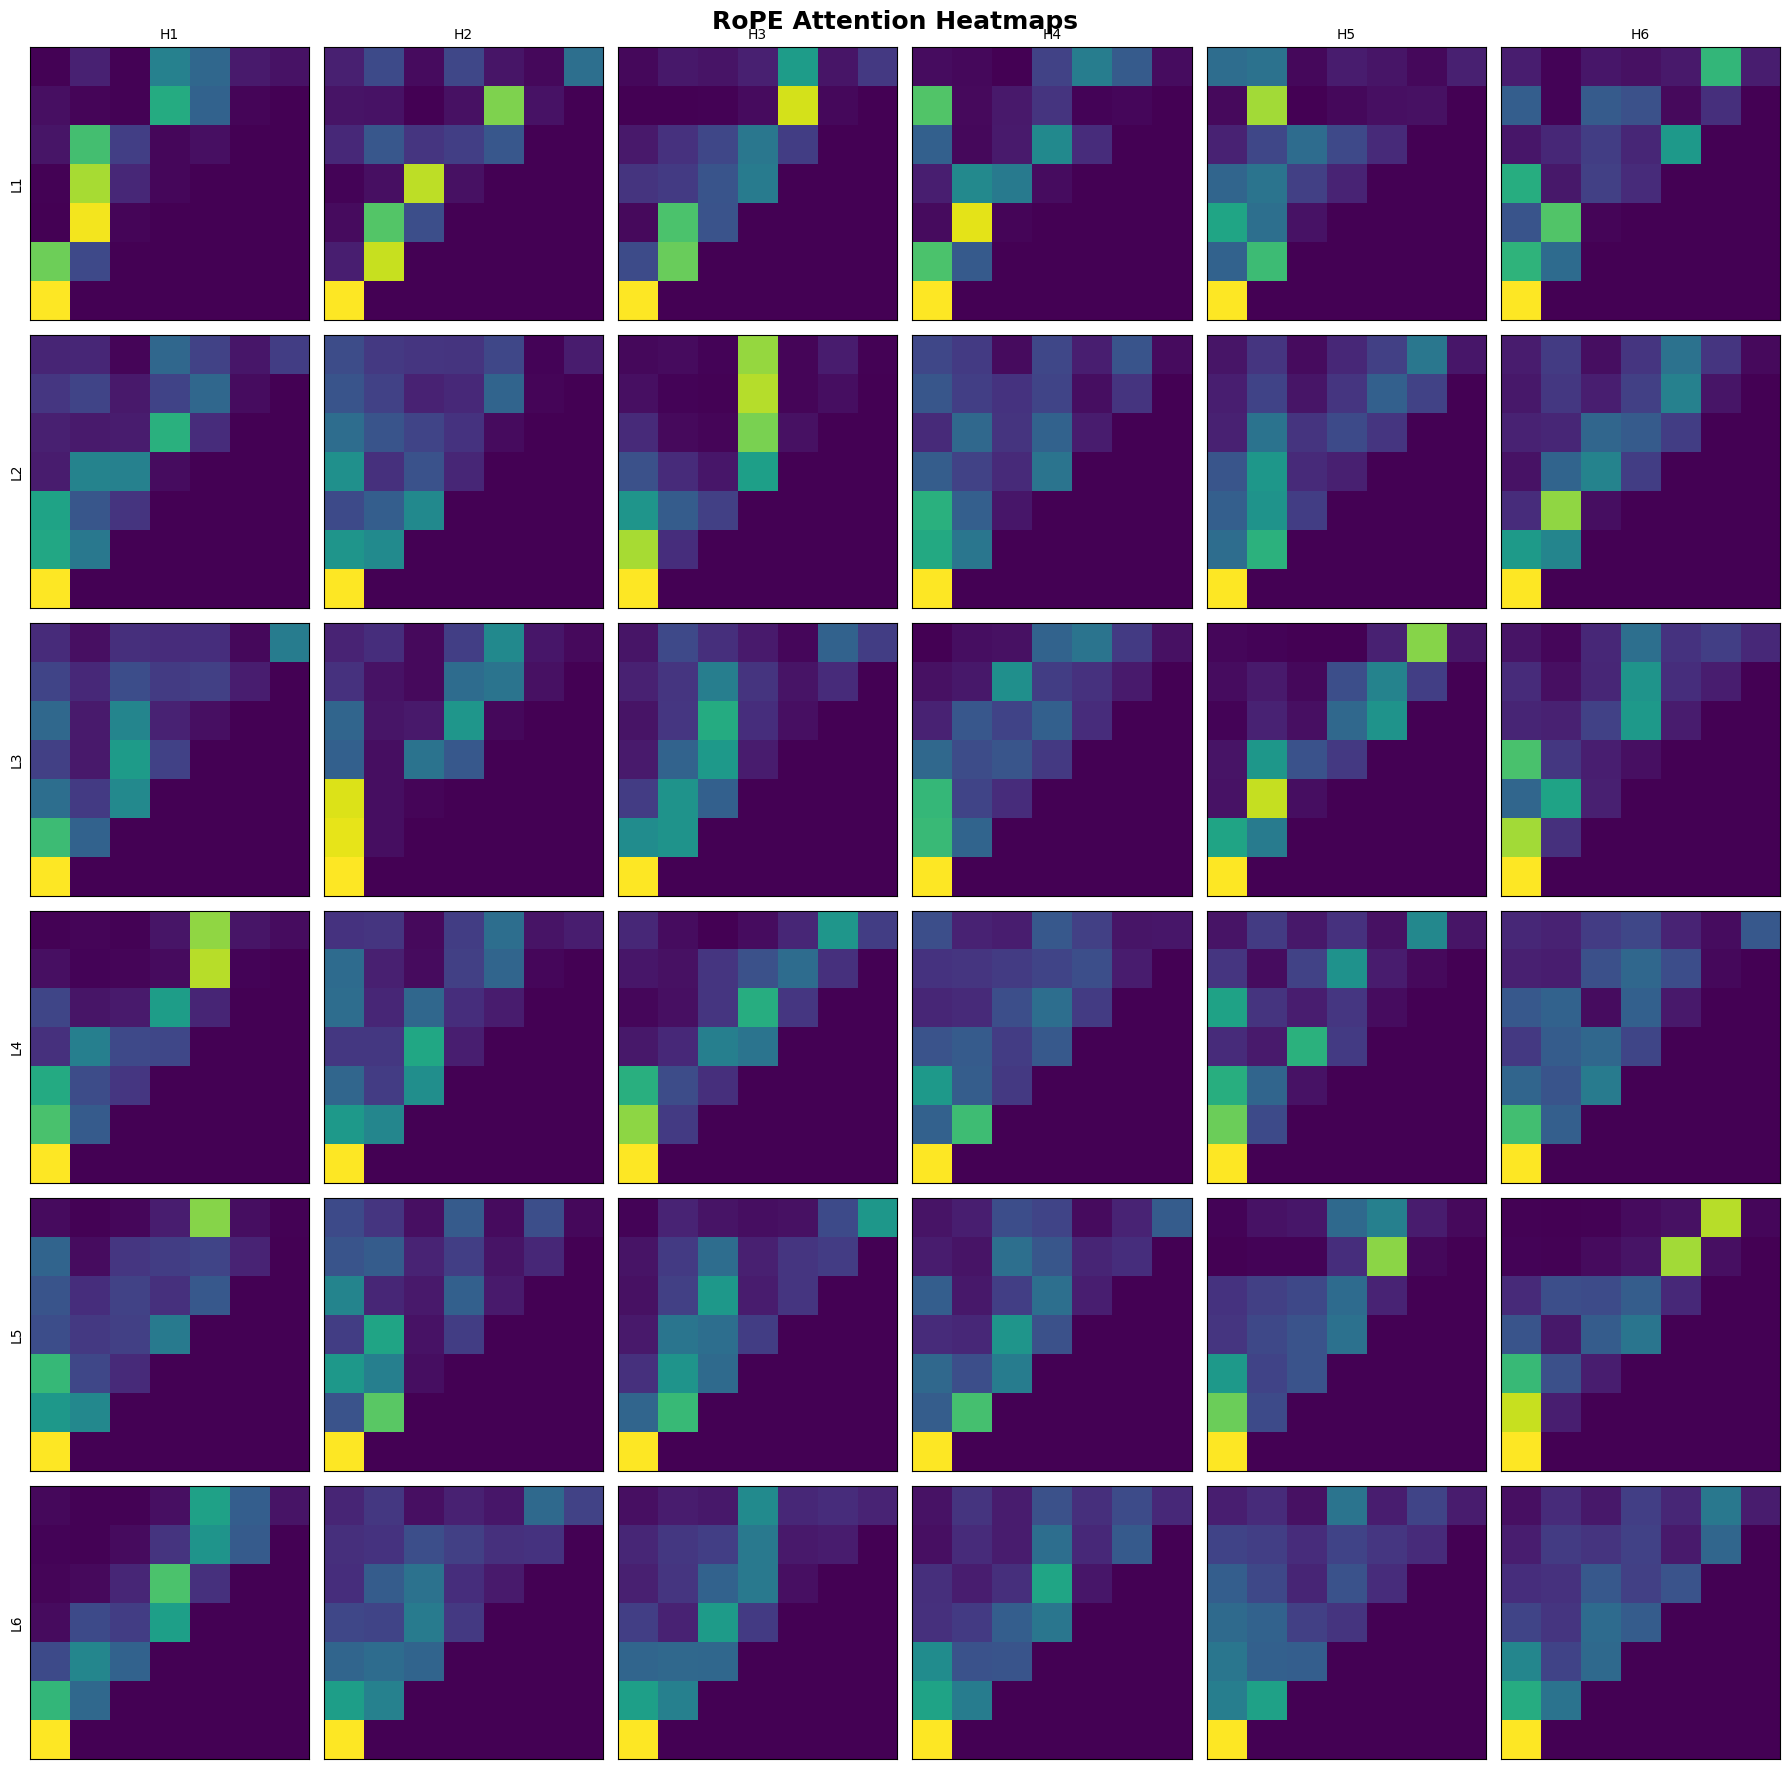

In [53]:
# ============================================================
# Attention Heatmaps (All Layers × All Heads)
# ============================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    nrows=6,
    ncols=6,
    figsize=(18,18)
)

for layer in range(6):

    for head in range(6):

        ax = axes[layer][head]

        att = attention[layer][0, head].cpu().numpy()

        im = ax.imshow(att, aspect="auto", origin="lower")

        ax.set_xticks([])
        ax.set_yticks([])

        if layer == 0:
            ax.set_title(f"H{head+1}", fontsize=10)

        if head == 0:
            ax.set_ylabel(f"L{layer+1}", fontsize=10)

fig.suptitle(
    "RoPE Attention Heatmaps",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "rope_attention_heatmaps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [54]:
# ============================================================
# Use a real validation sample
# ============================================================

loader = create_loader(64)

x, y = next(iter(loader))

# Take only the first example
x = x[:1].to(DEVICE)

tokens = x[0].cpu().tolist()

print("Number of tokens:", len(tokens))

print("\nDecoded text:\n")
print(tokenizer.decode(tokens))

Number of tokens: 64

Decoded text:

an idea. He used the magic toy to shrink all his toys. Now, they were easy to put away. After dinner, Tim went upstairs to play. He looked for his toy car and toy bear. They were still very small. Tim was sad. He wanted to play with them, but they were too small. He used the magic toy to make


In [55]:
# ============================================================
# Extract attention for a real sequence
# ============================================================

with torch.no_grad():
    logits, loss, attention = rope256(x)

print("Layers :", len(attention))
print("Shape  :", attention[0].shape)

Layers : 6
Shape  : torch.Size([1, 6, 64, 64])


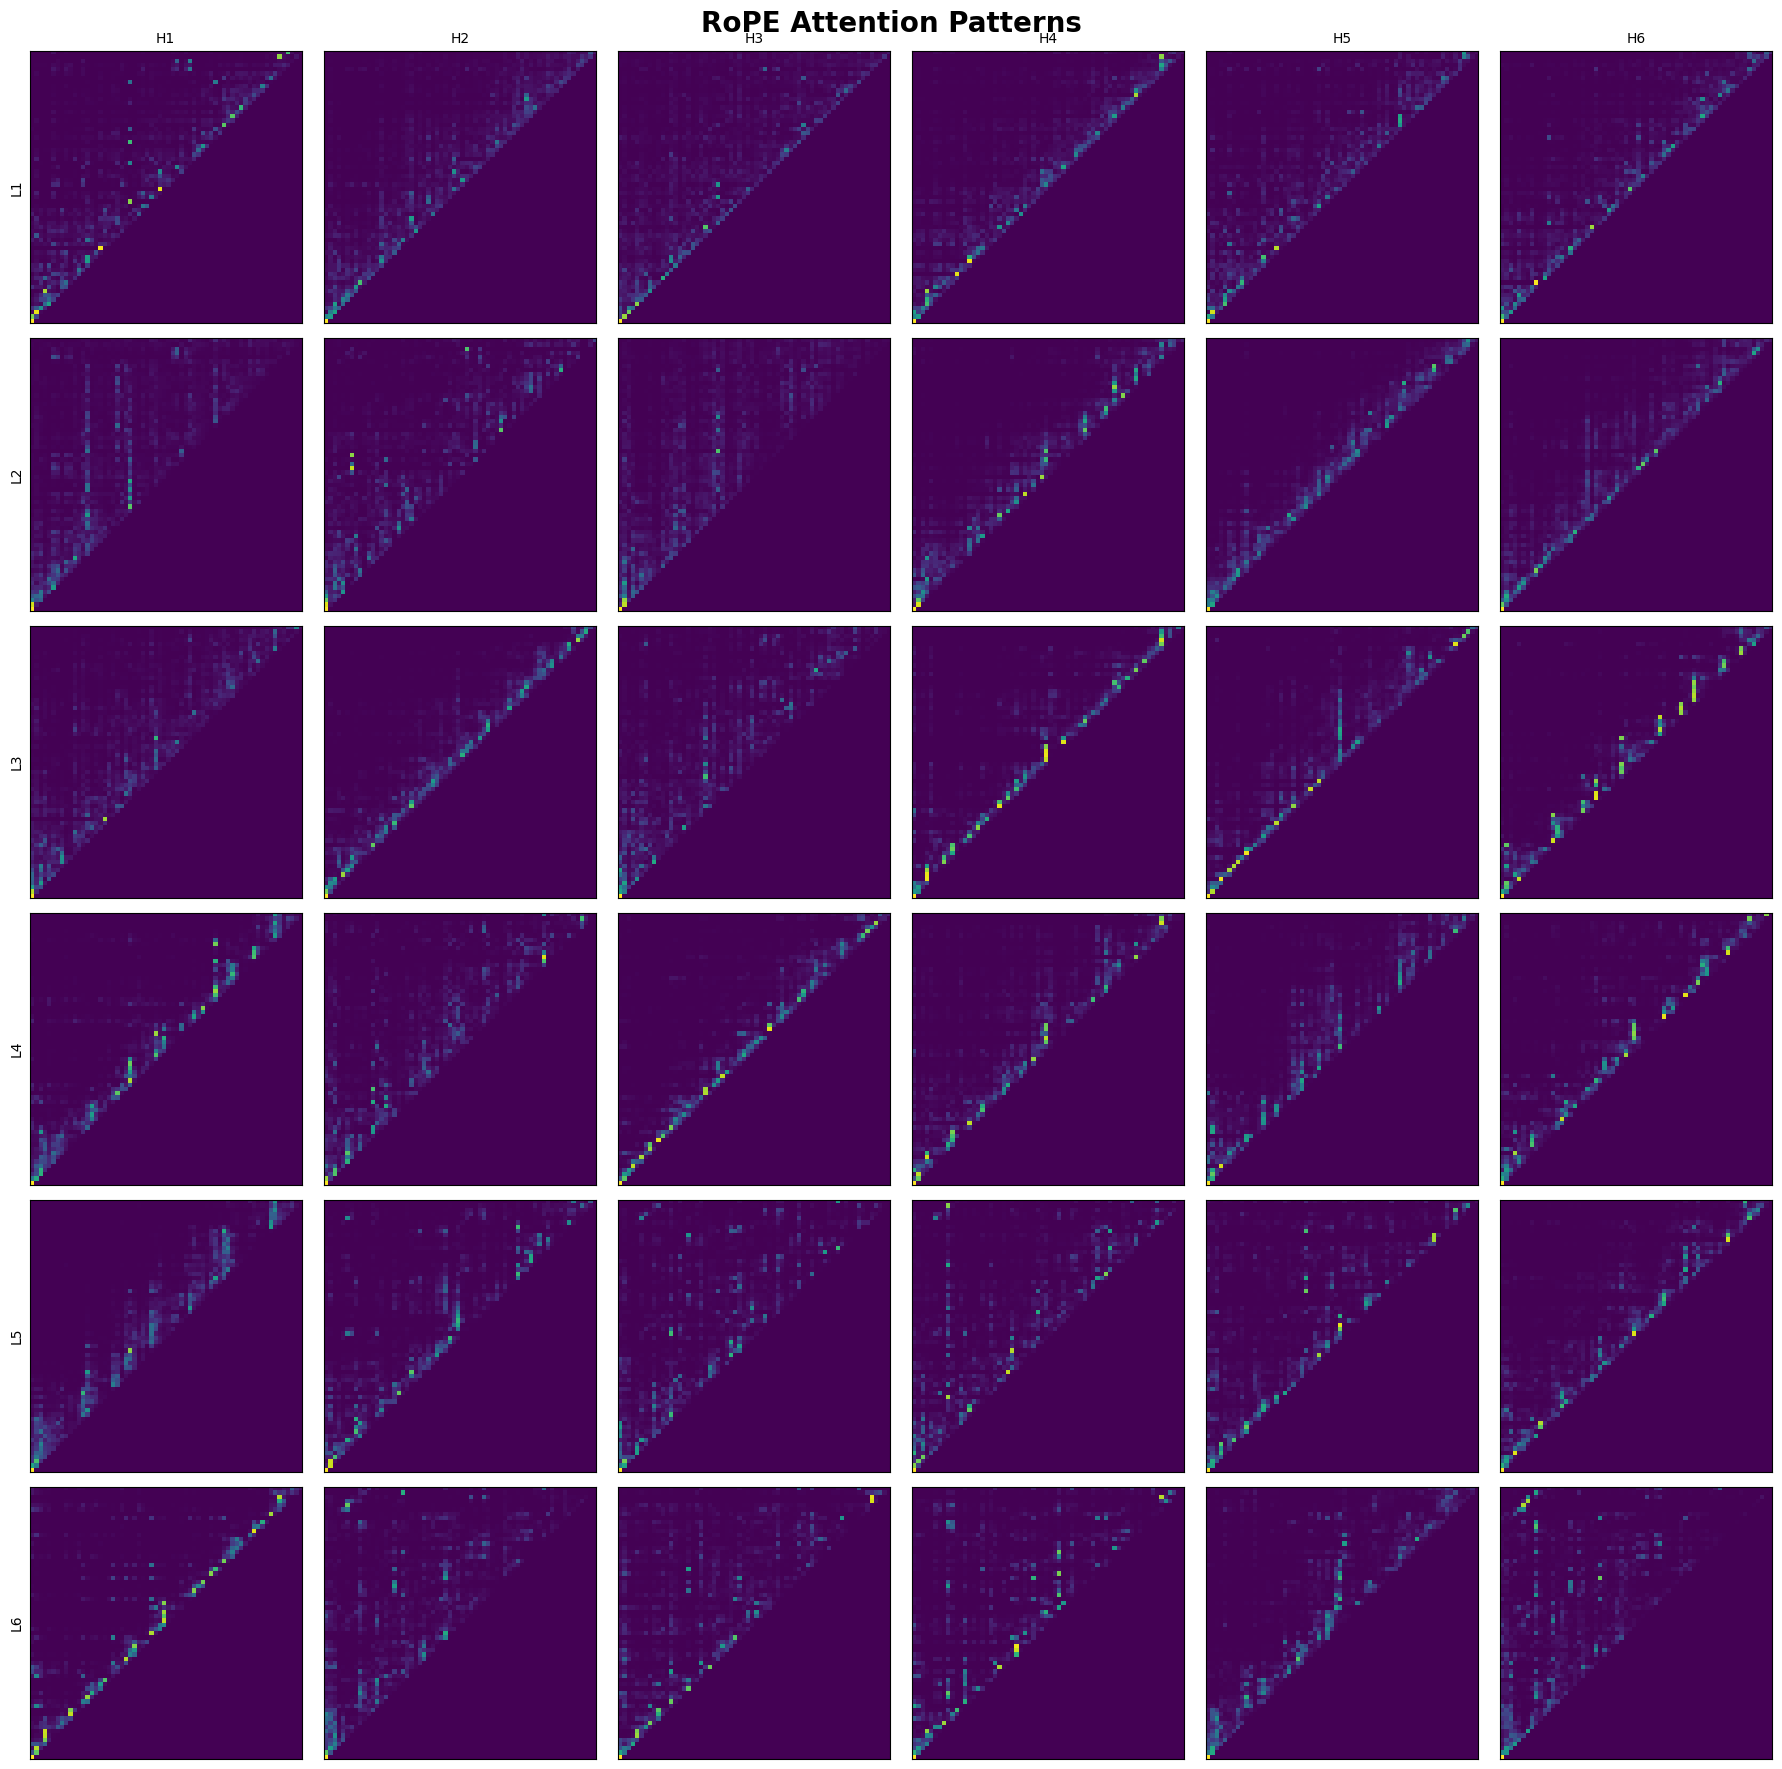

In [56]:
# ============================================================
# RoPE Attention Heatmaps
# ============================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(6, 6, figsize=(18,18))

for layer in range(6):

    for head in range(6):

        att = attention[layer][0, head].cpu().numpy()

        ax = axes[layer, head]

        im = ax.imshow(
            att,
            cmap="viridis",
            interpolation="nearest",
            origin="lower"
        )

        ax.set_xticks([])
        ax.set_yticks([])

        if layer == 0:
            ax.set_title(f"H{head+1}", fontsize=10)

        if head == 0:
            ax.set_ylabel(f"L{layer+1}", fontsize=10)

fig.suptitle(
    "RoPE Attention Patterns",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "rope_attention_heatmaps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [57]:
# ============================================================
# Load Learned Model
# ============================================================

import gc

try:
    del rope256
except:
    pass

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

learned256 = load_eval_model("learned", 256)

print("Learned model loaded.")

Model parameters: 12,318,720
Learned model loaded.


In [58]:
# ============================================================
# Extract Learned Attention
# ============================================================

with torch.no_grad():
    _, _, attention = learned256(x)

print("Layers :", len(attention))
print("Shape  :", attention[0].shape)

Layers : 6
Shape  : torch.Size([1, 6, 64, 64])


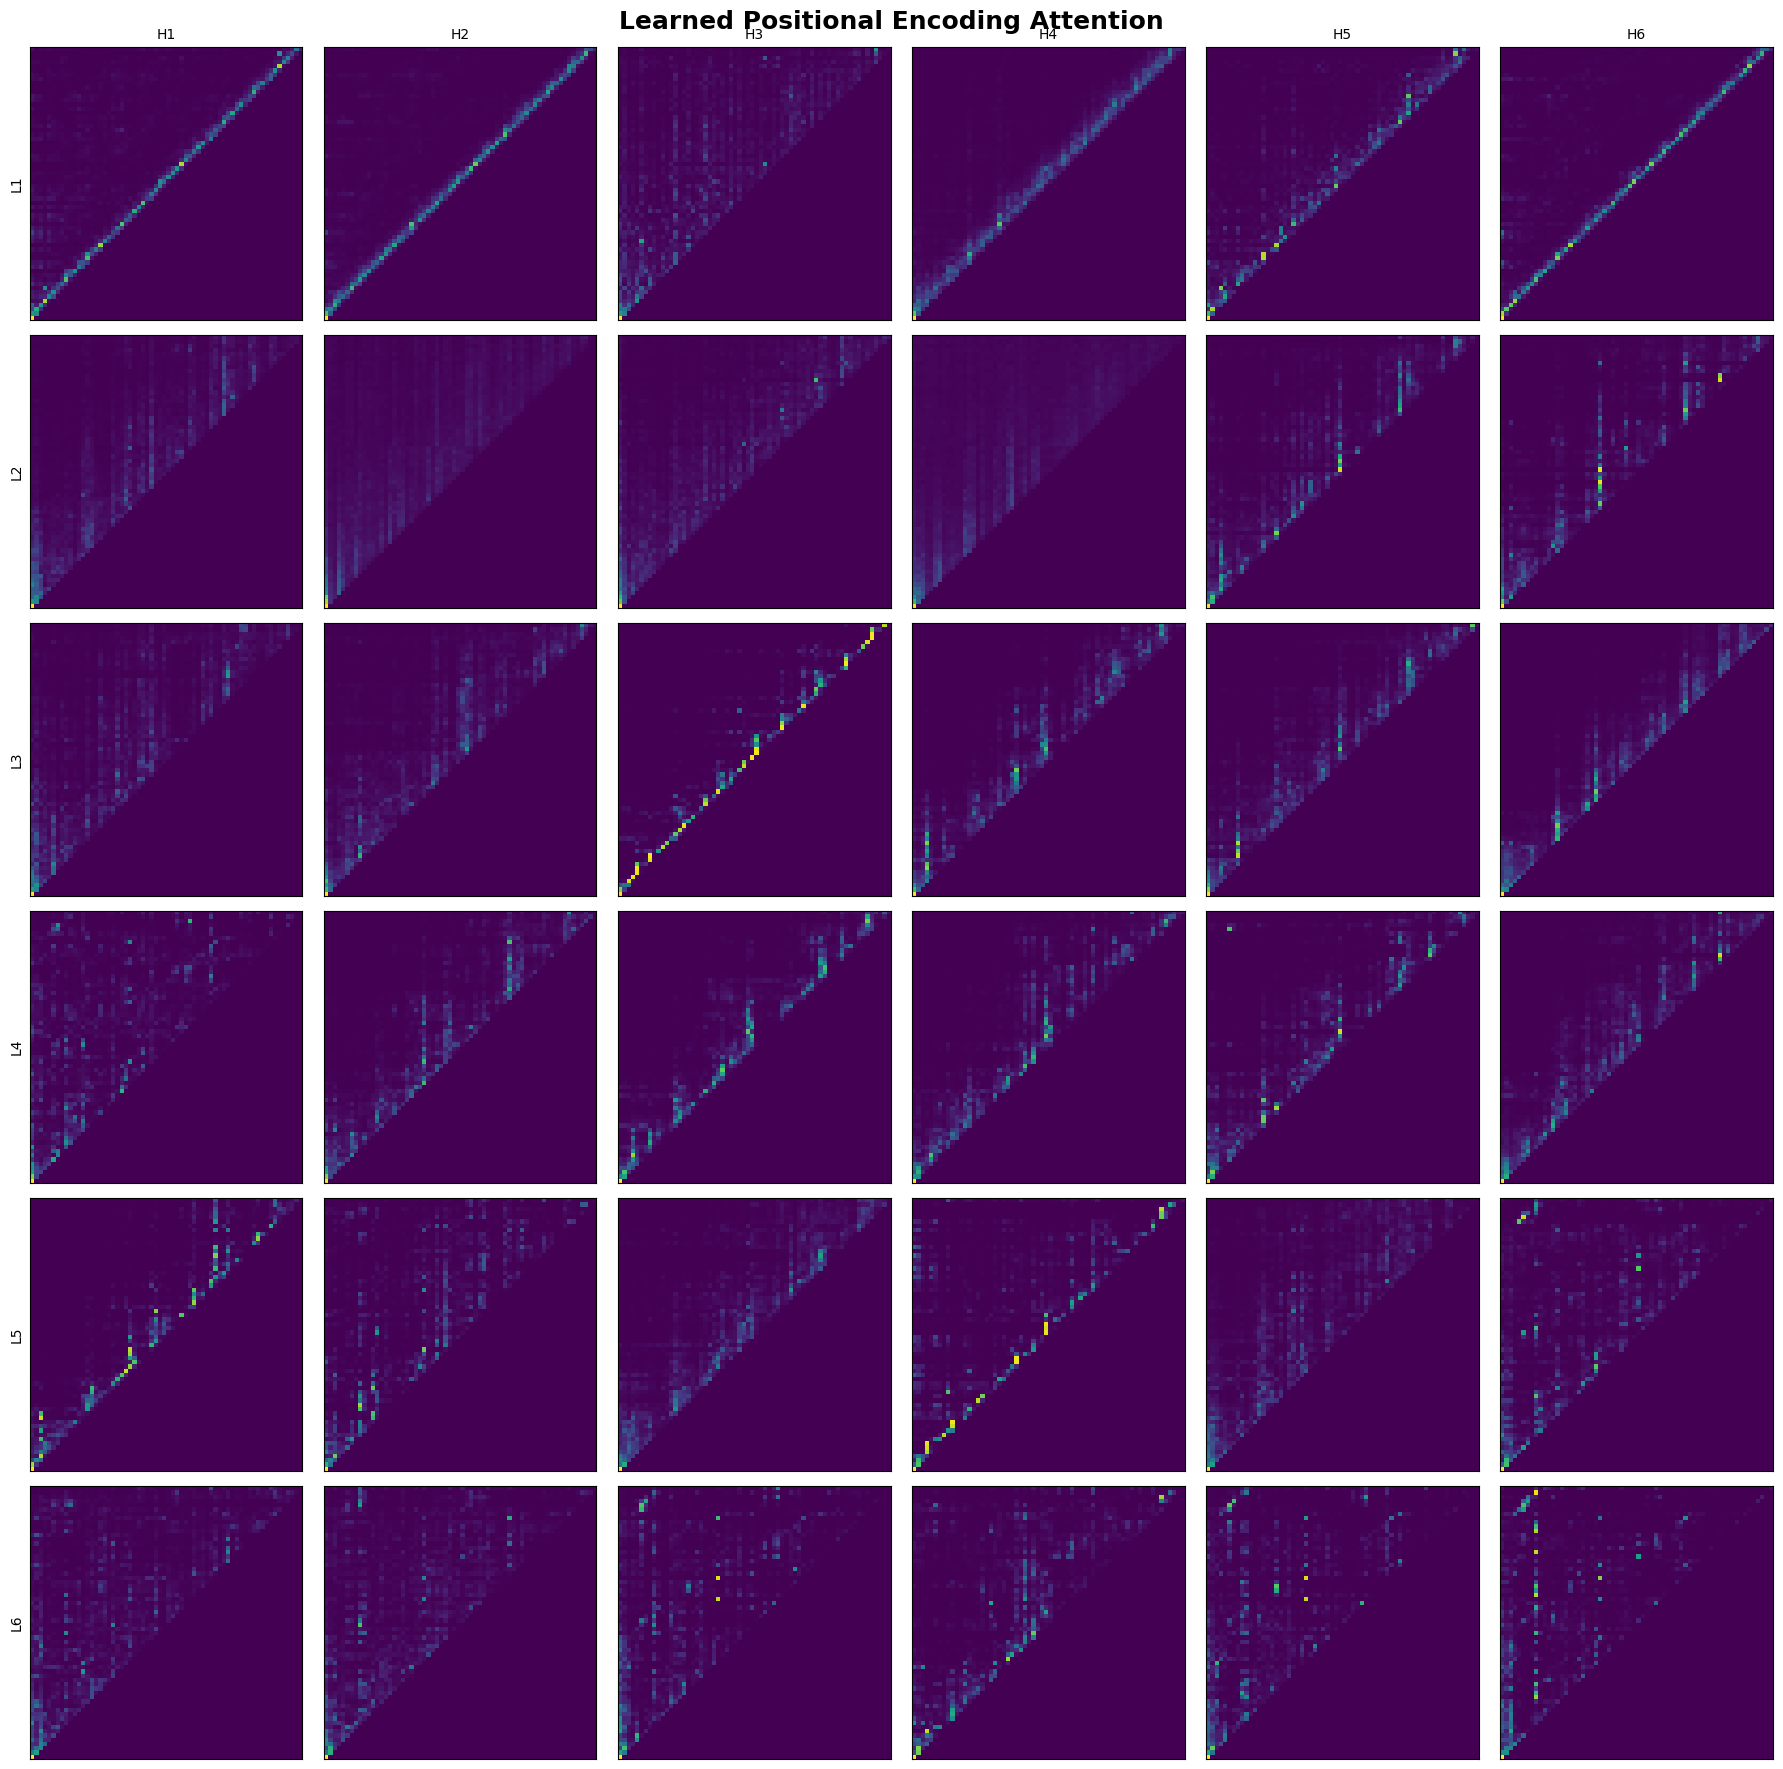

In [59]:
# ============================================================
# Learned Attention Heatmaps
# ============================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(6, 6, figsize=(18,18))

for layer in range(6):

    for head in range(6):

        att = attention[layer][0, head].cpu().numpy()

        ax = axes[layer, head]

        ax.imshow(
            att,
            cmap="viridis",
            origin="lower",
            interpolation="nearest"
        )

        ax.set_xticks([])
        ax.set_yticks([])

        if layer == 0:
            ax.set_title(f"H{head+1}", fontsize=10)

        if head == 0:
            ax.set_ylabel(f"L{layer+1}", fontsize=10)

fig.suptitle(
    "Learned Positional Encoding Attention",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "learned_attention_heatmaps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [60]:
# ============================================================
# Load Sinusoidal Model
# ============================================================

del learned256

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

sin256 = load_eval_model("sinusoidal", 256)

print("Sinusoidal model loaded.")

Model parameters: 12,220,416
Sinusoidal model loaded.


In [61]:
# ============================================================
# Extract Sinusoidal Attention
# ============================================================

with torch.no_grad():
    _, _, attention = sin256(x)

print("Layers :", len(attention))
print("Shape  :", attention[0].shape)


Layers : 6
Shape  : torch.Size([1, 6, 64, 64])


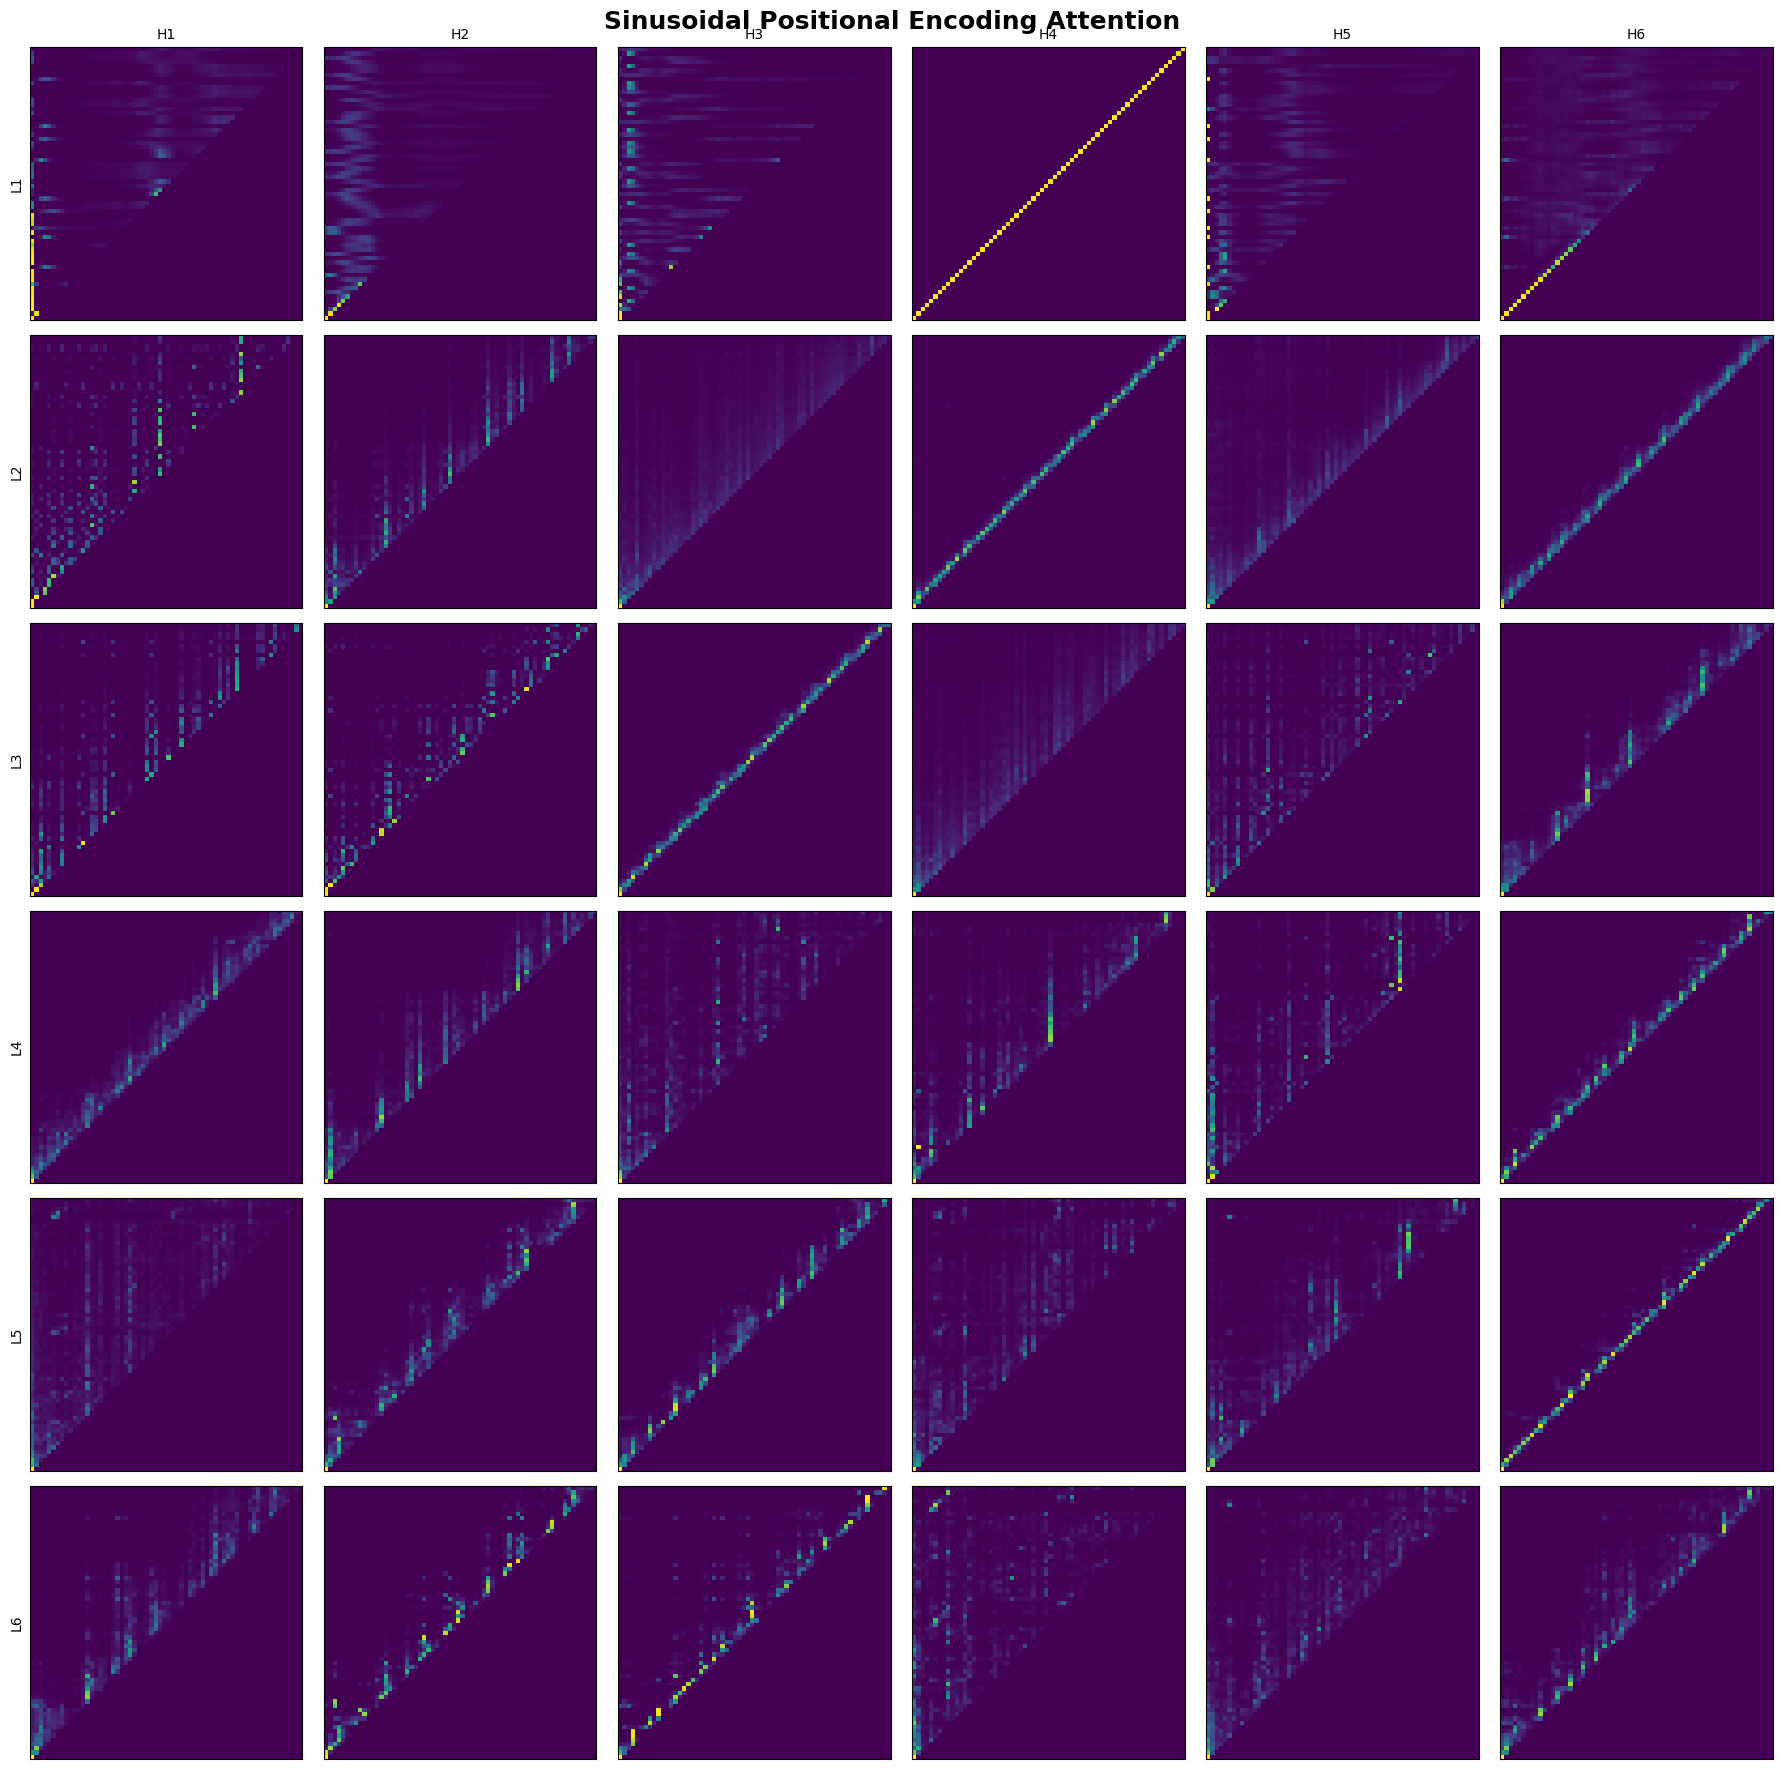

In [62]:
# ============================================================
# Sinusoidal Attention Heatmaps
# ============================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(6, 6, figsize=(18,18))

for layer in range(6):

    for head in range(6):

        att = attention[layer][0, head].cpu().numpy()

        ax = axes[layer, head]

        ax.imshow(
            att,
            cmap="viridis",
            origin="lower",
            interpolation="nearest"
        )

        ax.set_xticks([])
        ax.set_yticks([])

        if layer == 0:
            ax.set_title(f"H{head+1}", fontsize=10)

        if head == 0:
            ax.set_ylabel(f"L{layer+1}", fontsize=10)

fig.suptitle(
    "Sinusoidal Positional Encoding Attention",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "sinusoidal_attention_heatmaps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [63]:
# ============================================================
# Compare Saved Heatmaps
# ============================================================

print("Saved files:")
print(" - rope_attention_heatmaps.png")
print(" - learned_attention_heatmaps.png")
print(" - sinusoidal_attention_heatmaps.png")

Saved files:
 - rope_attention_heatmaps.png
 - learned_attention_heatmaps.png
 - sinusoidal_attention_heatmaps.png


In [65]:
# ============================================================
# Reload Learned Model
# ============================================================

import gc

try:
    del sin256
except:
    pass

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

learned256 = load_eval_model("learned", 256)

print("Learned model loaded.")

Model parameters: 12,318,720
Learned model loaded.


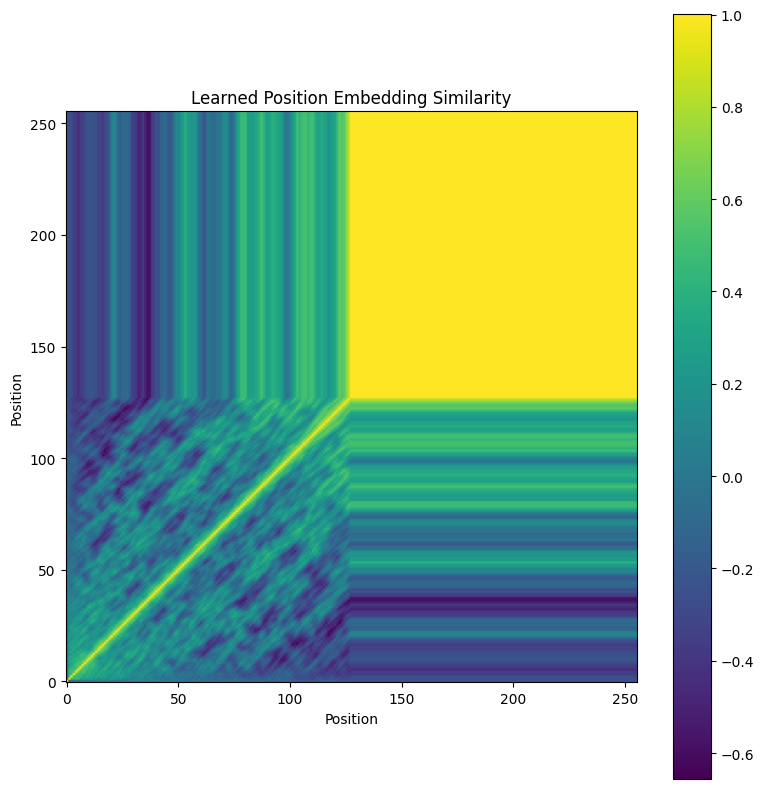

In [66]:
# ============================================================
# Learned Position Embedding Similarity
# ============================================================

import torch.nn.functional as F
import matplotlib.pyplot as plt

emb = learned256.pos_encoding.pos_embed.weight.detach().cpu()

emb = F.normalize(emb, dim=1)

similarity = emb @ emb.T

plt.figure(figsize=(8,8))

plt.imshow(similarity, cmap="viridis", origin="lower")

plt.colorbar()

plt.title("Learned Position Embedding Similarity")

plt.xlabel("Position")

plt.ylabel("Position")

plt.tight_layout()

plt.savefig(
    "learned_position_similarity.png",
    dpi=300
)

plt.show()

In [67]:
del learned256

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

sin256 = load_eval_model("sinusoidal", 256)

Model parameters: 12,220,416


In [70]:
# ============================================================
# Check what variables currently exist
# ============================================================

print("learned256" in globals())
print("rope256" in globals())
print("sin256" in globals())

False
False
True


In [71]:
# ============================================================
# Reload the Learned model
# ============================================================

import gc
import torch

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

learned256 = load_eval_model("learned", 256)

print("\nVariable exists:", "learned256" in globals())
print("Model type:", type(learned256).__name__)
print("Parameter count:", sum(p.numel() for p in learned256.parameters()))

Model parameters: 12,318,720

Variable exists: True
Model type: GPT
Parameter count: 12318720


In [72]:
print(type(learned256.pos_encoding))
print(learned256.pos_encoding.__class__.__name__)

<class 'positional_encoding.LearnedPositionalEncoding'>
LearnedPositionalEncoding


Embedding shape: torch.Size([256, 384])


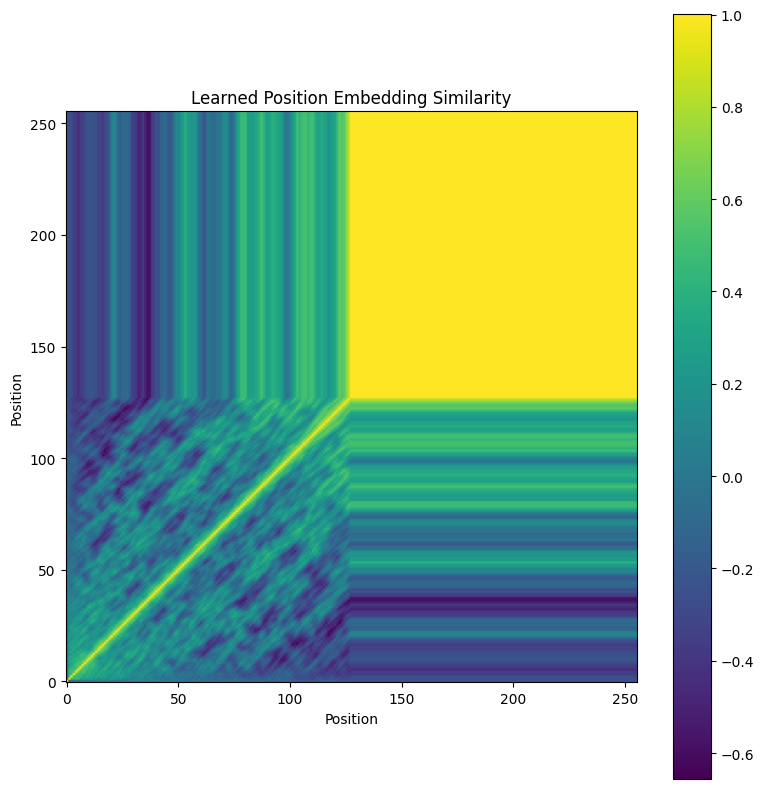

In [73]:
# ============================================================
# Learned Position Embedding Similarity
# ============================================================

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Get learned position embedding matrix
emb = learned256.pos_encoding.pos_embed.weight.detach().cpu()

print("Embedding shape:", emb.shape)

# Normalize embeddings
emb = F.normalize(emb, p=2, dim=1)

# Cosine similarity matrix
similarity = emb @ emb.T

plt.figure(figsize=(8, 8))

plt.imshow(
    similarity.numpy(),
    cmap="viridis",
    origin="lower"
)

plt.colorbar()

plt.title("Learned Position Embedding Similarity")

plt.xlabel("Position")
plt.ylabel("Position")

plt.tight_layout()

plt.savefig(
    "learned_position_similarity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [74]:
# ============================================================
# Load Sinusoidal Model
# ============================================================

del learned256

import gc
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

sin256 = load_eval_model("sinusoidal", 256)

print("Sinusoidal model loaded.")

Model parameters: 12,220,416
Sinusoidal model loaded.


Embedding shape: torch.Size([512, 384])


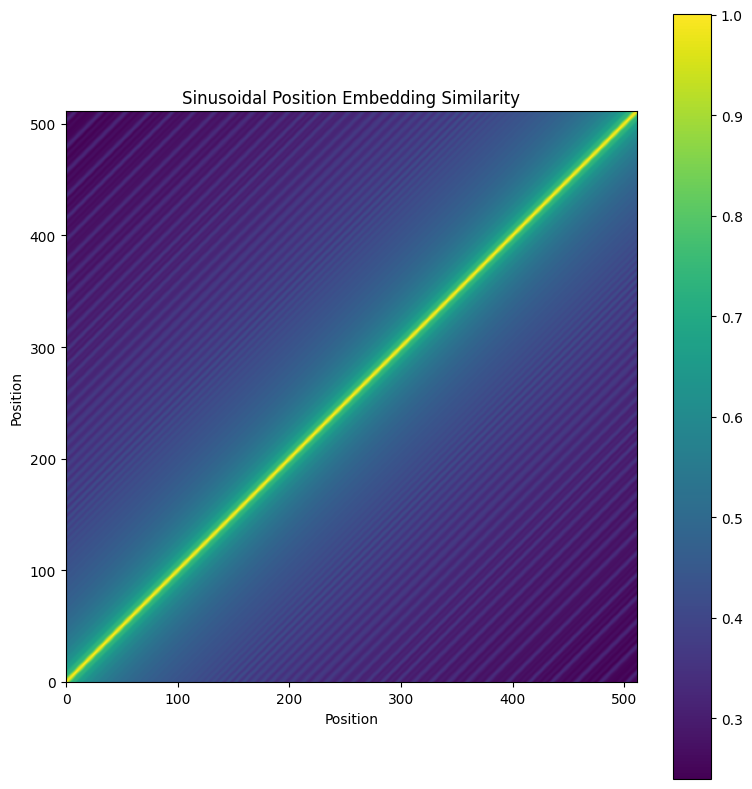

In [75]:
# ============================================================
# Sinusoidal Position Embedding Similarity
# ============================================================

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Get sinusoidal position embeddings
emb = sin256.pos_encoding.pe[0].detach().cpu()

print("Embedding shape:", emb.shape)

# Normalize embeddings
emb = F.normalize(emb, p=2, dim=1)

# Cosine similarity matrix
similarity = emb @ emb.T

plt.figure(figsize=(8,8))

plt.imshow(
    similarity.numpy(),
    cmap="viridis",
    origin="lower"
)

plt.colorbar()

plt.title("Sinusoidal Position Embedding Similarity")

plt.xlabel("Position")
plt.ylabel("Position")

plt.tight_layout()

plt.savefig(
    "sinusoidal_position_similarity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [76]:
# ============================================================
# Load All Three Models
# ============================================================

import gc

try:
    del sin256
except:
    pass

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

rope = load_eval_model("rope", 256)
learned = load_eval_model("learned", 256)
sin = load_eval_model("sinusoidal", 256)

print("All models loaded.")

Model parameters: 12,220,416
Model parameters: 12,318,720
Model parameters: 12,220,416
All models loaded.


In [77]:
# ============================================================
# Better Text Generation
# ============================================================

@torch.no_grad()
def generate_text(
    model,
    prompt,
    max_new_tokens=100,
    temperature=0.8,
    top_k=40
):

    model.eval()

    ids = tokenizer.encode(prompt)

    x = torch.tensor(ids).unsqueeze(0).to(DEVICE)

    for _ in range(max_new_tokens):

        x_cond = x[:, -256:]

        logits, _, _ = model(x_cond)

        logits = logits[:, -1, :] / temperature

        if top_k is not None:

            values, _ = torch.topk(logits, top_k)

            logits[logits < values[:, [-1]]] = -float("inf")

        probs = torch.softmax(logits, dim=-1)

        next_token = torch.multinomial(probs, 1)

        x = torch.cat([x, next_token], dim=1)

        if next_token.item() == tokenizer.eos_token_id:
            break

    return tokenizer.decode(x[0].tolist())

In [78]:
prompt = "Once upon a time"

print("="*80)
print("RoPE")
print("="*80)
print(generate_text(rope, prompt))

print("\n")

print("="*80)
print("Learned")
print("="*80)
print(generate_text(learned, prompt))

print("\n")

print("="*80)
print("Sinusoidal")
print("="*80)
print(generate_text(sin, prompt))

RoPE
Once upon a time there was a little girl who was very curious. One day, she went on an adventure and saw a big gate. She was so excited and she wanted to open it. The little girl asked the gate, "Can I open the gate?" The gate replied, "No, sweetie! It is too hard for you to open. I want you to touch it." The little girl thanked the gate and stepped inside. The gate was dark and full of fears. She watched as it opened and felt something soft and warm. She


Learned
Once upon a time there was a small cat named Kitty. Kitty loved to play with her best friend, a dog named Buddy. One day, Kitty and Buddy decided to have a fun day in the park. They ran around and played tag and hide-and-seek. But when they were playing, Kitty got very tired. She thought of a plan to rest and have a nap. Buddy found a cozy spot under a big tree. Kitty curled up on a tree and closed her eyes. She felt much better and soon fell asleep. When


Sinusoidal
Once upon a time there was a little girl named Jane.